<a href="https://colab.research.google.com/github/Prktriesitout/ScipyAssignments/blob/main/ScipyAssignmenta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Resizing the Image

Write a Python function to resize the image image.png to half its original dimensions using the scipy.ndimage.zoom function

/tmp/ipykernel_870/3275448884.py:9: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = iio.imread('photo.png', mode='L')


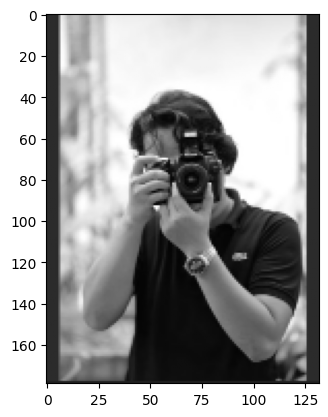

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy import interpolate
from scipy import fft
from scipy import signal
import imageio as iio

img = iio.imread('photo.png', mode='L')
resized_img = ndimage.zoom(img, 0.5)
plt.imshow(resized_img, cmap='gray')
plt.show()

Using the scipy.ndimage.rotate function, rotate the image image.png by 45 degrees. Ensure that the image is not cropped after rotation.

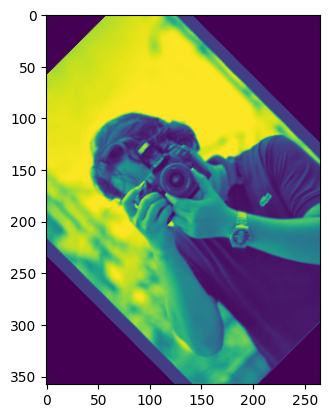

In [6]:
rotated_img = ndimage.rotate(img, 45, reshape=False)
plt.imshow(rotated_img)
plt.show()

Apply a Gaussian filter to smooth the image using the scipy.ndimage.gaussian_filter function. Experiment with different values of sigma and display the output.

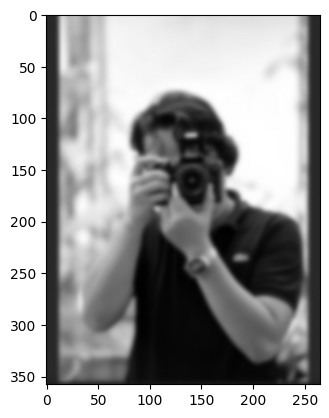

In [7]:
gaussabian_img = ndimage.gaussian_filter(img, sigma=2)
plt.imshow(gaussabian_img, cmap='gray')
plt.show()

Perform edge detection on the image by calculating the gradient magnitude using the scipy.ndimage.sobel function. Combine the Sobel filters along both axes to visualize the edges.

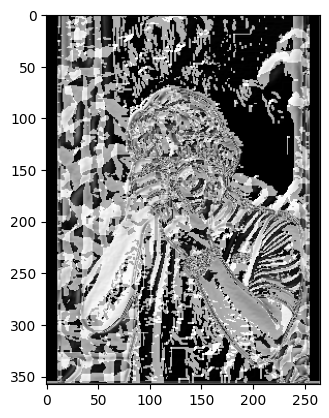

In [8]:
sobel_x = ndimage.sobel(img, axis=0, mode='constant')
sobel_y = ndimage.sobel(img, axis=1, mode='constant')
edge_img = np.hypot(sobel_x, sobel_y)
plt.imshow(edge_img, cmap='gray')
plt.show()

Convert the grayscale version of the image into a binary image using a threshold value. Use scipy.ndimage.threshold to achieve this.

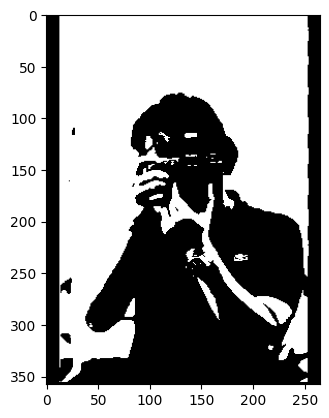

In [9]:
threshold_value = 128
binary_img = img > threshold_value
plt.imshow(binary_img, cmap='gray')
plt.show()

Morphological Operations

Perform morphological operations (e.g., erosion, dilation) on the binary image created in the previous question using scipy.ndimage.binary_erosion and binary_dilation.

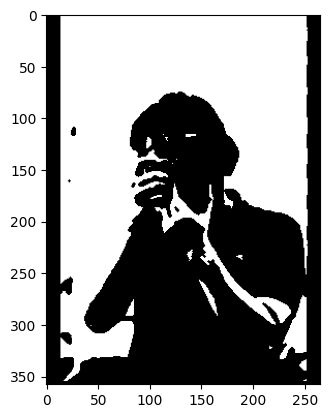

In [10]:
eroded_img = ndimage.binary_erosion(binary_img)
dilated_img = ndimage.binary_dilation(binary_img)
plt.imshow(eroded_img, cmap='gray')
plt.show()

Labeling Connected Components

Identify and label connected components in the binary version of the image using scipy.ndimage.label. Count the number of distinct objects in the image.

In [11]:
labeled_img, num_objects = ndimage.label(binary_img)
print("Number of objects:", num_objects)

Number of objects: 37


Calculate statistics like mean, variance, and standard deviation of pixel values in the image using scipy.ndimage.measurements.

In [12]:
img_mean = np.mean(img)
img_var = np.var(img)
img_std = np.std(img)
print("Mean:", img_mean)
print("Variance:", img_var)
print("Standard Deviation:", img_std)

Mean: 137.52366396121008
Variance: 7872.097948502235
Standard Deviation: 88.72484403199724


Perform a 2D Fourier Transform on the image using scipy.fft.fft2 to analyze its frequency components. Plot the magnitude spectrum.

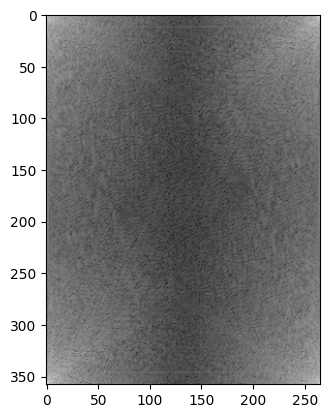

In [13]:
noise = np.random.normal(0, 0.1, img.shape)
noisy_img = img + noise
fft_result = fft.fft2(noisy_img)
magnitude_spectrum = np.abs(fft_result)
plt.imshow(np.log(1 + magnitude_spectrum), cmap='gray')
plt.show()

Given a noisy sine wave with missing data points, use the scipy.interpolate.interp1d function to interpolate the missing values.
Hint: Generate a sine wave and randomly remove some points. Use different interpolation methods (linear, quadratic, cubic) and compare the results.

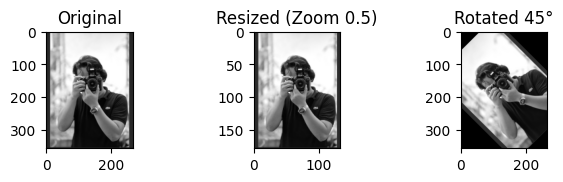

In [16]:
plt.subplot(3, 3, 1), plt.imshow(img, cmap='gray'), plt.title('Original')
plt.subplot(3, 3, 2), plt.imshow(resized_img, cmap='gray'), plt.title('Resized (Zoom 0.5)')
plt.subplot(3, 3, 3), plt.imshow(rotated_img, cmap='gray'), plt.title('Rotated 45°')
plt.tight_layout()
plt.show()

Load an image and scale it up to double its size using 2D interpolation (scipy.interpolate.interp2d). Experiment with different interpolation methods (linear, cubic) to see how each affects the image quality.
Hint: Convert the image to grayscale, then apply interpolation to resize it

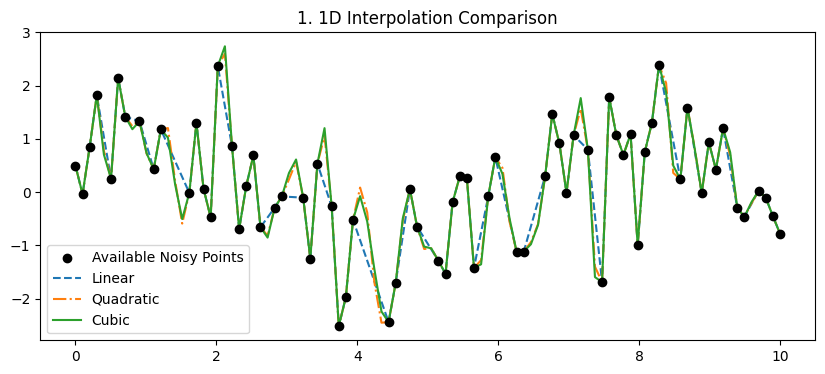

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy import interpolate
from scipy import fft
from scipy import signal

np.random.seed(42)

x_full = np.linspace(0,10,100)
y_full = np.sin(x_full)
y_noisy = y_full + np.random.normal(0,1,100)

mask = np.ones(len(x_full), dtype=bool)
drop_indices = np.random.choice(np.arange(1, len(x_full) - 1), size=30, replace=False)
mask[drop_indices] = False

x_known, y_known = x_full[mask], y_noisy[mask]

f_linear = interpolate.interp1d(x_known, y_known, kind='linear')
f_quad = interpolate.interp1d(x_known, y_known, kind='quadratic')
f_cubic = interpolate.interp1d(x_known, y_known, kind='cubic')

plt.figure(figsize=(10, 4))
plt.scatter(x_known, y_known, color='black', label='Available Noisy Points', zorder=5)
plt.plot(x_full, f_linear(x_full), '--', label='Linear')
plt.plot(x_full, f_quad(x_full), '-.', label='Quadratic')
plt.plot(x_full, f_cubic(x_full), '-', label='Cubic')
plt.title('1. 1D Interpolation Comparison')
plt.legend()
plt.show()

Generate a noisy sine wave and fit a B-spline curve using scipy.interpolate.splrep and splev. Experiment with different values for the smoothing parameter s to control how closely the spline fits the data.
Challenge: Plot the original sine wave and the smoothed B-spline fit on the same graph

/tmp/ipykernel_870/1214488298.py:2: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img = iio.imread('photo.png', mode='L')


TypeError: meshgrid() got an unexpected keyword argument 'index'

Applying B-Spline Interpolation in 2D

Create a grid of sample points from a function (e.g., z = sin(x) * cos(y)) and apply B-spline interpolation using scipy.interpolate.RectBivariateSpline. Evaluate the B-spline on a denser grid to create a smooth surface plot.
Hint: Use numpy.meshgrid to create a grid of x and y values.

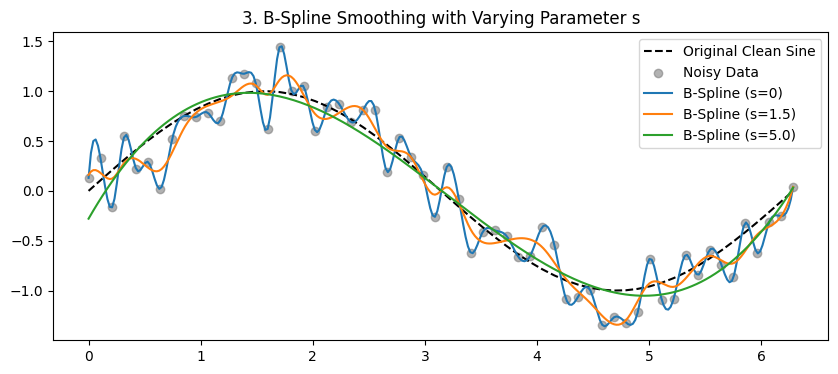

In [21]:
x_bs = np.linspace(0, 2 * np.pi, 60)
y_bs_clean = np.sin(x_bs)
y_bs_noisy = y_bs_clean + np.random.normal(0, 0.2, size=x_bs.shape)

x_dense = np.linspace(0, 2 * np.pi, 300)

plt.figure(figsize=(10, 4))
plt.plot(x_bs, y_bs_clean, 'k--', label='Original Clean Sine')
plt.scatter(x_bs, y_bs_noisy, color='gray', alpha=0.6, label='Noisy Data')

for s_val in [0, 1.5, 5.0]:
    tck = interpolate.splrep(x_bs, y_bs_noisy, s=s_val)
    y_spline = interpolate.splev(x_dense, tck)
    plt.plot(x_dense, y_spline, label=f'B-Spline (s={s_val})')

plt.title('3. B-Spline Smoothing with Varying Parameter s')
plt.legend()
plt.show()

Applying a Median Filter to Denoise a Signal

Create a noisy sinusoidal signal and apply a median filter to reduce the noise. Use scipy.ndimage.median_filter and experiment with different filter sizes.
Question: How does changing the filter size affect the balance between noise reduction and signal distortion?

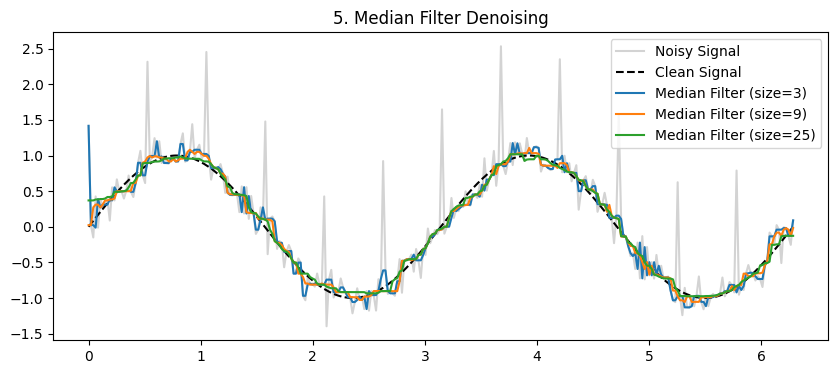

In [22]:
t = np.linspace(0, 2 * np.pi, 300)
sig_clean = np.sin(2 * t)
# Add impulse (salt-and-pepper) + Gaussian noise
sig_noisy = sig_clean + np.random.normal(0, 0.15, size=t.shape)
sig_noisy[::25] += 1.5  # Spike noise

plt.figure(figsize=(10, 4))
plt.plot(t, sig_noisy, color='lightgray', label='Noisy Signal')
plt.plot(t, sig_clean, 'k--', label='Clean Signal')

for size in [3, 9, 25]:
    filtered = ndimage.median_filter(sig_noisy, size=size)
    plt.plot(t, filtered, label=f'Median Filter (size={size})')

plt.title('5. Median Filter Denoising')
plt.legend()
plt.show()

Designing and Applying a Low-Pass Filter

Generate a noisy signal that contains both low and high frequencies. Design a low-pass Butterworth filter using scipy.signal.butter and apply it to the signal using scipy.signal.filtfilt.
Hint: Plot the original and filtered signals. Observe how the high-frequency noise is reduced after filtering.

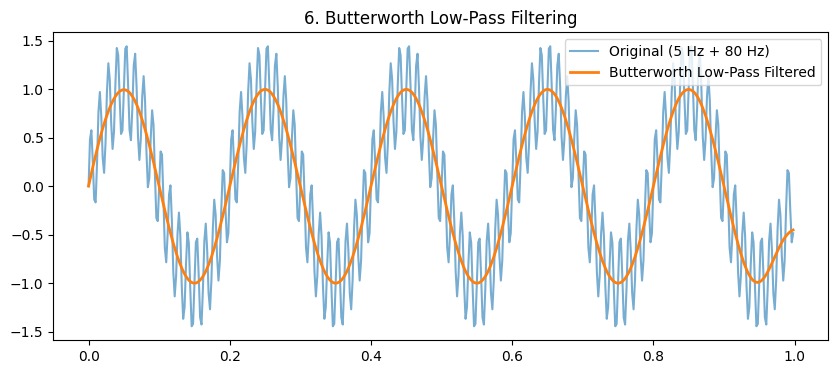

In [23]:
fs = 500.0  # Sampling frequency (Hz)
t_sig = np.linspace(0, 1.0, int(fs), endpoint=False)

# Low-freq signal (5 Hz) + High-freq noise (80 Hz)
low_freq = np.sin(2 * np.pi * 5 * t_sig)
high_freq = 0.5 * np.sin(2 * np.pi * 80 * t_sig)
combined_sig = low_freq + high_freq

# Design 4th-order Butterworth low-pass filter with 15 Hz cutoff
cutoff = 15.0
nyq = 0.5 * fs
b, a = signal.butter(N=4, Wn=cutoff / nyq, btype='low')
filtered_sig = signal.filtfilt(b, a, combined_sig)

plt.figure(figsize=(10, 4))
plt.plot(t_sig, combined_sig, alpha=0.6, label='Original (5 Hz + 80 Hz)')
plt.plot(t_sig, filtered_sig, linewidth=2, label='Butterworth Low-Pass Filtered')
plt.title('6. Butterworth Low-Pass Filtering')
plt.legend()
plt.show()

Load an image and apply a high-pass filter to enhance the edges using scipy.ndimage.gaussian_laplace. Experiment with different sigma values to control the strength of the high-pass filter.
Challenge: Display the original and high-pass-filtered images side by side for comparison.

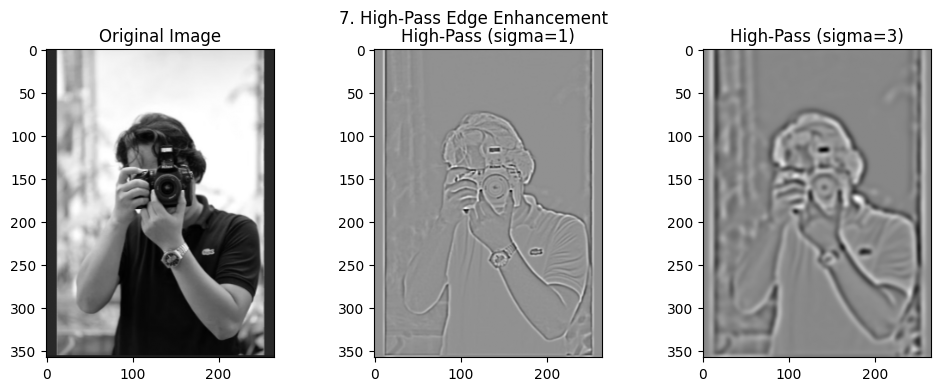

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img, cmap='gray')
axes[0].set_title('Original Image')

for idx, sigma in enumerate([1, 3], start=1):
    # Gaussian Laplace highlights rapid intensity changes (edges)
    hp_img = ndimage.gaussian_laplace(img.astype(float), sigma=sigma)
    axes[idx].imshow(hp_img, cmap='gray')
    axes[idx].set_title(f'High-Pass (sigma={sigma})')

plt.suptitle('7. High-Pass Edge Enhancement')
plt.show()

Generate a signal composed of multiple sine waves of different frequencies. Use scipy.fft.fft to compute the Fourier Transform of the signal and plot its magnitude spectrum.
Question: Identify the peaks in the frequency spectrum and relate them to the frequencies of the sine waves in the original signal.


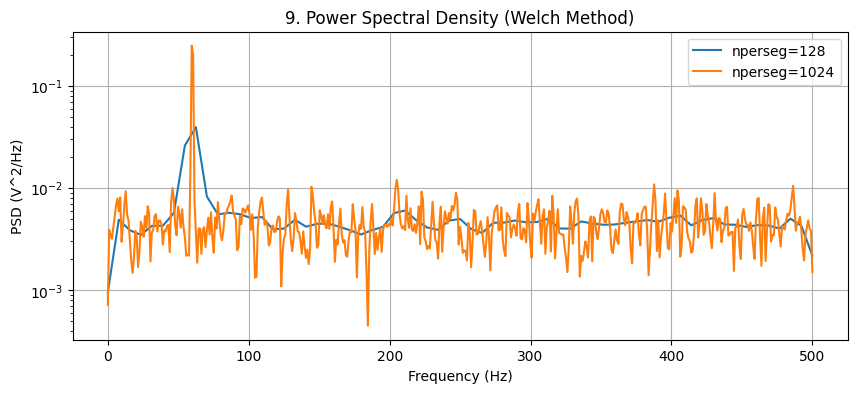

In [25]:
fs_psd = 1000.0
t_psd = np.linspace(0, 4.0, int(4 * fs_psd), endpoint=False)
# 60 Hz signal embedded in white noise
rand_sig = np.sin(2 * np.pi * 60 * t_psd) + np.random.normal(0, 1.5, size=t_psd.shape)

plt.figure(figsize=(10, 4))
for nperseg in [128, 1024]:
    freqs, psd = signal.welch(rand_sig, fs=fs_psd, nperseg=nperseg)
    plt.semilogy(freqs, psd, label=f'nperseg={nperseg}')

plt.title('9. Power Spectral Density (Welch Method)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('PSD (V^2/Hz)')
plt.legend()
plt.grid(True)
plt.show()

Generate a random time series signal, then use scipy.signal.welch to calculate its Power Spectral Density (PSD). Plot the PSD to analyze the dominant frequencies in the signal.
Hint: Adjust the nperseg parameter in welch to control the resolution of the PSD.

Generate a noisy sine wave and apply a Fourier Transform to observe the frequency components. Design a simple low-pass filter in the frequency domain (e.g., by zeroing out high-frequency components) and apply an inverse Fourier Transform to reconstruct the signal.
Challenge: Compare the reconstructed signal with the original to observe how well the noise is removed

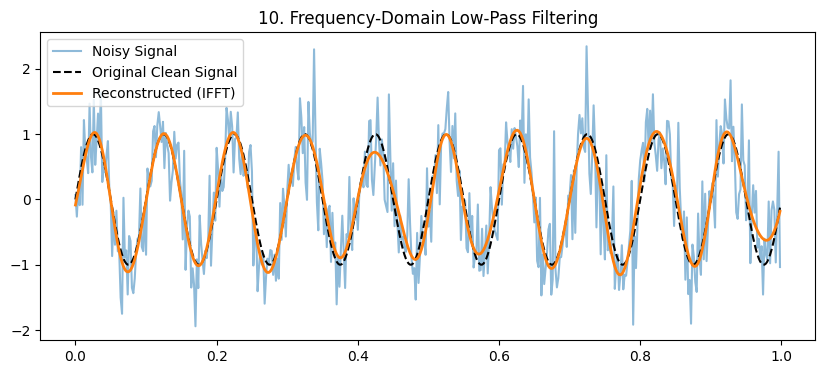

In [26]:
fs_fd = 500.0
t_fd = np.linspace(0, 1.0, int(fs_fd), endpoint=False)
clean_fd = np.sin(2 * np.pi * 10 * t_fd)
noisy_fd = clean_fd + np.random.normal(0, 0.5, size=t_fd.shape)

# Forward FFT
fft_vals = fft.fft(noisy_fd)
freqs_fd = fft.fftfreq(len(t_fd), 1 / fs_fd)

# Zero out frequencies above 20 Hz
fft_filtered = fft_vals.copy()
fft_filtered[np.abs(freqs_fd) > 20] = 0

# Inverse FFT to reconstruct time-domain signal
reconstructed_fd = np.real(fft.ifft(fft_filtered))

plt.figure(figsize=(10, 4))
plt.plot(t_fd, noisy_fd, alpha=0.5, label='Noisy Signal')
plt.plot(t_fd, clean_fd, 'k--', label='Original Clean Signal')
plt.plot(t_fd, reconstructed_fd, linewidth=2, label='Reconstructed (IFFT)')
plt.title('10. Frequency-Domain Low-Pass Filtering')
plt.legend()
plt.show()